In [1]:
"""
We are building a MULTI-AGENT system with a Supervisor.

    The Supervisor: reads the conversation and decides which agent should work next
                    (or FINISH when the question is fully answered).

    The Researcher: has a web search tool (Tavily, like 5-1), finds facts.

    The Math agent: has a calculator tool, does the arithmetic.

    The Writer:     has no tools, writes the final answer for the user. After the writer, the graph ends.

The researcher and the math agent report back to the Supervisor, so the graph looks like a hub with spokes.

    TAVILY_API_KEY and GOOGLE_API_KEY must be in your .env file.
""";

In [2]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated, Literal
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.graph.message import add_messages
from langgraph.types import Command
from langchain.agents import create_agent
from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from pydantic import BaseModel
from dotenv import load_dotenv

load_dotenv()

True

In [3]:
from langchain_google_genai import ChatGoogleGenerativeAI

llm = ChatGoogleGenerativeAI(
    model="gemini-3.1-flash-lite",
    temperature=0
)

"""from langchain_openai import ChatOpenAI
import os

llm = ChatOpenAI(
    openai_api_key=os.environ.get("OPENROUTER_API_KEY"),
    openai_api_base="https://openrouter.ai/api/v1",
    model_name="nvidia/nemotron-3-ultra-550b-a55b:free"
)""";

Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


In [4]:
# Tools
# web search: Tavily (TAVILY_API_KEY), the newer version of TavilySearchResults used in 5-1
search_tool = TavilySearch(max_results=2)

# calculator: same as 11_tools
@tool
def calculator(first_num: float, second_num: float, operation: str) -> dict:
    """
    Perform a basic arithmetic operation on two numbers.
    Supported operations: add, sub, mul, div
    """
    if operation == "add":
        result = first_num + second_num
    elif operation == "sub":
        result = first_num - second_num
    elif operation == "mul":
        result = first_num * second_num
    elif operation == "div":
        result = first_num / second_num if second_num != 0 else "Division by zero is not allowed"
    else:
        result = f"Unsupported operation '{operation}'"
    return {"first_num": first_num, "second_num": second_num, "operation": operation, "result": result}

In [5]:
# The agents
# each agent is a small ReAct agent (LLM + its OWN tools), exactly like the chatbot in 11_tools
# create_agent builds that "chat_node -> tools -> chat_node" loop for us

research_agent = create_agent(
    llm,
    tools=[search_tool],
    system_prompt="You are a researcher. Use the search tool to find facts. Report only the facts with numbers, no calculations."
)

math_agent = create_agent(
    llm,
    tools=[calculator],
    system_prompt="You are a math expert. ALWAYS use the calculator tool for every calculation. Report the result."
)

writer_agent = create_agent(
    llm,
    tools=[],
    system_prompt="You are a writer. Using the reports in the conversation, write a short and clear final answer for the user."
)

In [6]:
# state
class TeamState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]   # shared board: question + every agent's report
    steps: int                                             # how many times the supervisor has routed (safety limit)

In [7]:
# The supervisor does not answer anything itself. It only fills this "form":
# Literal means it can ONLY pick one of these names, so it cannot invent an agent
class Route(BaseModel):
    next: Literal["researcher", "math", "writer"]

router = llm.with_structured_output(Route)

SUPERVISOR_PROMPT = """You are a supervisor managing three agents:
- researcher: finds facts on the web
- math: does calculations with a calculator
- writer: writes the final answer for the user

Look at the conversation and pick who should work next.
Skip an agent if its work is not needed.
Pick the writer when the facts and calculations are ready."""

In [8]:
# graph nodes

def supervisor(state: TeamState):
    """Decides which agent works next. Command = go to a node AND update the state in one return."""
    steps = state.get("steps", 0)
    if steps >= 5:                                   # safety: never loop forever, let the writer finish
        return Command(goto="writer")

    decision = router.invoke([("system", SUPERVISOR_PROMPT)] + state["messages"])
    print(f"Supervisor -> {decision.next}")

    return Command(goto=decision.next, update={"steps": steps + 1})

In [9]:
def run_agent(agent, name: str, state: TeamState):
    """Run one agent on the conversation and put its last answer on the board, signed with its name."""
    result = agent.invoke({"messages": state["messages"]})
    report = result["messages"][-1].text             # .text = plain string (Gemini 3 .content is a list of parts)
    return {"messages": [HumanMessage(content=report, name=name)]}

def researcher_node(state: TeamState):
    return run_agent(research_agent, "researcher", state)

def math_node(state: TeamState):
    return run_agent(math_agent, "math", state)

def writer_node(state: TeamState):
    return run_agent(writer_agent, "writer", state)

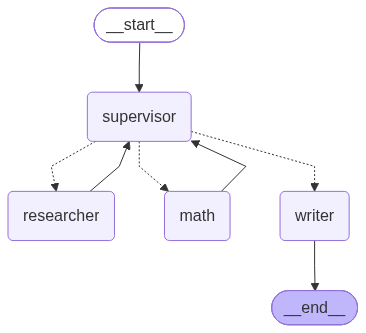

In [10]:
# graph structure
graph = StateGraph(TeamState)

graph.add_node("supervisor", supervisor, destinations=("researcher", "math", "writer"))
graph.add_node("researcher", researcher_node)
graph.add_node("math", math_node)
graph.add_node("writer", writer_node)

graph.add_edge(START, "supervisor")

# researcher and math report back to the supervisor (hub and spokes)
graph.add_edge("researcher", "supervisor")
graph.add_edge("math", "supervisor")

# the writer's answer is the final answer
graph.add_edge("writer", END)

team = graph.compile()

team

In [11]:
# Question that needs ALL agents: facts (researcher) + arithmetic (math) + final answer (writer)
out = team.invoke({"messages": [HumanMessage(content="What are the heights of Mount Everest and K2 in metres? How much taller is Everest than K2?")]})

print(out["messages"][-1].content)

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


Supervisor -> researcher


Supervisor -> writer


Mount Everest stands at **8,848.86 metres**, while K2 stands at **8,611 metres**. Consequently, Mount Everest is **237.86 metres** taller than K2.


In [12]:
# message trace to check who did what

for msg in out["messages"]:
    print(f"--- {msg.name or msg.__class__.__name__} ---")
    print(f" CONTENT: {msg.content[:300]}\n")

--- HumanMessage ---
 CONTENT: What are the heights of Mount Everest and K2 in metres? How much taller is Everest than K2?

--- researcher ---
 CONTENT: The official height of Mount Everest is 8,848.86 metres. The widely accepted official height of K2 is 8,611 metres. Based on these figures, Mount Everest is 237.86 metres taller than K2.

--- writer ---
 CONTENT: Mount Everest stands at **8,848.86 metres**, while K2 stands at **8,611 metres**. Consequently, Mount Everest is **237.86 metres** taller than K2.



In [13]:
# Question that needs ONLY the math agent and the writer: the supervisor should skip the researcher
out = team.invoke({"messages": [HumanMessage(content="What is 1234 multiplied by 56?")]})

print(out["messages"][-1].content)

Supervisor -> math


Supervisor -> writer


1234 multiplied by 56 is 69,104.


In [14]:
# stream: watch the agents work one by one
for step in team.stream({"messages": [HumanMessage(content="What is the population of Pune and Nashik? What is the total?")]}):
    for node, update in step.items():
        if update and "messages" in update:
            print(f"[{node}] {update['messages'][-1].content[:200]}\n")

Supervisor -> researcher


[researcher] Based on 2024 population estimates:

*   **Pune (City):** 4,436,000
*   **Nashik (City):** 2,108,000

The total of these two figures is 6,544,000.



Supervisor -> writer


[writer] Based on 2024 estimates, the populations of the two cities are as follows:

*   **Pune:** 4,436,000
*   **Nashik:** 2,108,000

The combined total population for both cities is **6,544,000**.

